# 3D Convolutional Motion Classifier

A short clip shows a disk moving right, left, down or up. Start position and disk size are randomised independently of the class.

In [1]:
from pathlib import Path
import sys

start = Path.cwd()
for parent in (start, *start.parents):
    if (parent / "gallery" / "__init__.py").is_file():
        sys.path.insert(0, str(parent))
        break
else:
    raise RuntimeError("Open this example inside the Machine Learning collection.")

## Spatiotemporal filters

The convolutional kernels extend across both space and time. Global pooling removes dependence on the final position.

In [2]:
import matplotlib.pyplot as plt
import torch
from torch import nn
from gallery.vision import moving_clips, class_scores, confusion
from gallery.neural import seed_cpu, train_classifier


def motion_net():
    return nn.Sequential(
        nn.Conv3d(1, 12, (3, 3, 3)),
        nn.ReLU(),
        nn.MaxPool3d((1, 2, 2)),
        nn.Conv3d(12, 24, (3, 3, 3)),
        nn.ReLU(),
        nn.AdaptiveAvgPool3d(1),
        nn.Flatten(),
        nn.Linear(24, 4),
    )

## Train on clips

A new random stream generates the held-out clips. Class numbers 0 through 3 mean right, left, down and up.

Accuracy 1.000 | Balanced accuracy 1.000 | MCC 1.000
              precision    recall  f1-score   support

           0      1.000     1.000     1.000        40
           1      1.000     1.000     1.000        40
           2      1.000     1.000     1.000        40
           3      1.000     1.000     1.000        40

    accuracy                          1.000       160
   macro avg      1.000     1.000     1.000       160
weighted avg      1.000     1.000     1.000       160

Log loss 0.095 | Macro ROC AUC (one-vs-rest) 1.000
Macro average precision 1.000 | Multiclass Brier 0.032


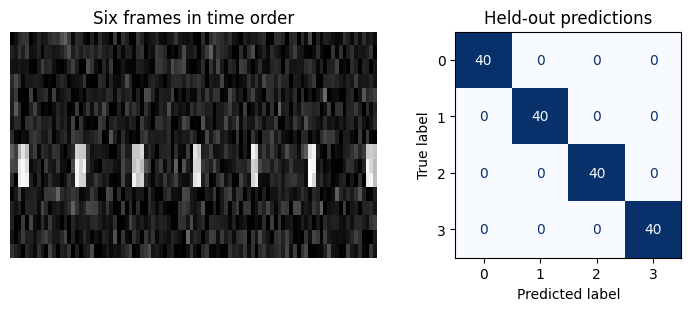

In [3]:
seed_cpu()
train, y = moving_clips(640, 17)
test, y_test = moving_clips(160, 89)
net = motion_net()
history = train_classifier(net, train[:, None], y, epochs=16, lr=0.003)
with torch.no_grad():
    prob = net(torch.tensor(test[:, None])).softmax(1).numpy()
class_scores(y_test, prob.argmax(1), prob)
fig, (a, b) = plt.subplots(1, 2, figsize=(7.5, 3), constrained_layout=True)
a.imshow(torch.tensor(test[0]).permute(1, 0, 2).reshape(16, -1), cmap="gray", aspect="auto")
a.axis("off")
a.set_title("Six frames in time order")
confusion(b, y_test, prob.argmax(1))
plt.show()

## Reading the result

Each clip has periodic boundaries, so starting position gives no systematic class cue. The held-out scores refer to this four-motion family.

## References

[Tran et al., Learning Spatiotemporal Features with 3D Convolutional Networks (2015)](https://arxiv.org/abs/1412.0767)

[Image and video generators and evaluation](../../../gallery/vision.py)